# EDA of the cleaned tables: `clients` (one row per observation) and `txns` (one row per distinct transaction)

Input: the two tables returned by `clean_data.load_and_clean`. Because customers can have several observations,
every join and every customer-level summary here uses the **observation key** (`cifwithcheckdigit` + `obs_id`).

**Sections**
1. Setup, load and overview
2. Clients table: quality, target, cohorts, segments, numeric variables, label validation, repeat customers
3. Transactions table: volume, amounts and balances, categories, timing and window coverage
4. Linking the tables: behaviour in the window vs the target
5. Automatic red-flag checklist

## 1. Setup, load and overview

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100); pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110

# ---------------- CONFIG: edit these ----------------
SOURCE = "snapshot/snapshot.parquet"   # raw/snapshot file, cleaned on the fly by clean_data.load_and_clean
USE_SAVED = False                      # True: read cleaned/clients_clean.parquet and cleaned/transactions_clean.parquet
SAVED_DIR = "cleaned"
PLOT_SAMPLE = 1_000_000                # max transaction rows used for histograms
MIN_N = 30                             # minimum group size shown in rate tables

In [2]:
if USE_SAVED:
    clients = pd.read_parquet(f"{SAVED_DIR}/clients_clean.parquet")
    txns = pd.read_parquet(f"{SAVED_DIR}/transactions_clean.parquet")
    report = None
else:
    from clean_data import load_and_clean
    clients, txns, report = load_and_clean(SOURCE)

ID, OBS, M0, TARGET, PAY = "cifwithcheckdigit", "obs_id", "m0_monthenddate", "target_value", "payment_date"
TXN_DATE, TXN_TYPE, AMT, BAL, SPEND, CAT = "transactiondate", "trantypedesc", "amount", "balance", "spendgroup", "categoryname"
KEY = [ID, OBS] if OBS in clients.columns else [ID, M0]
for c in (M0, PAY):
    if c in clients: clients[c] = pd.to_datetime(clients[c])
clients[ID] = clients[ID].astype(str)

print(f"Observation key: {KEY}")
print(f"clients: {clients.shape}  |  txns: {txns.shape}")
print(f"memory: clients {clients.memory_usage(deep=True).sum()/1e6:,.1f} MB | txns {txns.memory_usage(deep=True).sum()/1e6:,.1f} MB")
display(clients.dtypes.to_frame("clients dtype").join(txns.dtypes.to_frame("txns dtype"), how="outer"))

Observation key: ['cifwithcheckdigit', 'obs_id']
Observation-level columns (16): ['obs_seq', 'm0_monthenddate', 'm0_arrearsamount', 'crccreditlimit', 'due_count', 'payment_count', 'm0_total_due_with_arrears', 'total_paid', 'target_value', 'target_rule', 'new_to_arrears_flag', 'product_group', 'm0_start_cd_group', 'payment_date', 'collectionsmethodname', 'exclude_flag']
Transaction-level columns (8): ['days_from_payment', 'tx_period', 'transactiondate', 'trantypedesc', 'amount', 'balance', 'spendgroup', 'categoryname']
Ignored when matching duplicates (row counters): []
Building clients table ...
  4,482,046 raw rows -> 10,499 observations (4,999 customers) (1s)
Building transactions table ...
  transactions batch 1/1: 3,534,387 rows kept (3s)
CLIENTS (one row per observation)                                             
  raw rows (observation fields repeated per transaction)             4,482,046
  observations after cleaning                                           10,499
  distinct

,clients dtype,txns dtype
amount,NaN,float64
amount_slog,NaN,float32
arrears_share_of_due,float32,NaN
balance,NaN,float64
balance_slog,NaN,float32
categoryname,NaN,category
cifwithcheckdigit,str,category
collectionsmethodname,category,NaN
crccreditlimit,float64,NaN
crccreditlimit_slog,float32,NaN


In [3]:
# Cleaning report (if the cleaner was run here) and a size reconciliation
if report:
    print("Column split used:", report["levels"])
    keys = ["clients_raw_rows", "clients_after", "customers", "max_observations_per_customer", "txn_raw_rows",
            "txn_exact_duplicates_removed", "txn_rows_without_client", "txn_after", "clients_without_transactions"]
    display(pd.Series({k: report[k] for k in keys if k in report}, name="value").to_frame())

n_cust, n_obs = clients[ID].nunique(), len(clients)
print(f"Customers: {n_cust:,} | observations: {n_obs:,} | transactions: {len(txns):,}")
tpo = txns.groupby(KEY, observed=True).size()
print(f"Transactions per observation: median {tpo.median():,.0f}, mean {tpo.mean():,.0f}, max {tpo.max():,}")
print(f"Observations without any transaction: {n_obs - len(tpo):,}")

Column split used: {'client': ['obs_seq', 'm0_monthenddate', 'm0_arrearsamount', 'crccreditlimit', 'due_count', 'payment_count', 'm0_total_due_with_arrears', 'total_paid', 'target_value', 'target_rule', 'new_to_arrears_flag', 'product_group', 'm0_start_cd_group', 'payment_date', 'collectionsmethodname', 'exclude_flag'], 'transaction': ['days_from_payment', 'tx_period', 'transactiondate', 'trantypedesc', 'amount', 'balance', 'spendgroup', 'categoryname'], 'ignored_for_duplicates': []}


,value
clients_raw_rows,4482046
clients_after,10499
customers,4999
max_observations_per_customer,6
txn_raw_rows,4482046
txn_exact_duplicates_removed,947659
txn_rows_without_client,0
txn_after,3534387
clients_without_transactions,0


Customers: 4,999 | observations: 10,499 | transactions: 3,534,387
Transactions per observation: median 246, mean 337, max 3,469
Observations without any transaction: 0


## 2. Clients table (one row per observation)

In [4]:
dq = pd.DataFrame({"missing_n": clients.isna().sum(), "missing_%": clients.isna().mean() * 100, "n_unique": clients.nunique()})
display(dq.sort_values("missing_%", ascending=False))
display(clients.select_dtypes("number").describe(percentiles=[.01, .05, .5, .95, .99]).T)
for c in (M0, PAY):
    if c in clients: print(f"{c:18s} {clients[c].min().date()} -> {clients[c].max().date()}  (NaT: {clients[c].isna().sum():,})")

,missing_n,missing_%,n_unique
cifwithcheckdigit,0,0.0000,4999
obs_id,0,0.0000,10499
arrears_share_of_due,0,0.0000,10496
crccreditlimit_slog,0,0.0000,237
total_paid_slog,0,0.0000,6842
m0_total_due_with_arrears_slog,0,0.0000,10408
m0_arrearsamount_slog,0,0.0000,9401
exclude_flag,0,0.0000,1
collectionsmethodname,0,0.0000,3
payment_date,0,0.0000,174


,count,mean,std,min,1%,5%,50%,95%,99%,max
obs_id,"10,499.0000","126,319.6390","72,563.5255",167.0000,"2,231.9800","12,927.9000","128,158.0000","238,850.1000","248,560.0200","250,996.0000"
obs_seq,"10,499.0000",1.9221,1.1216,1.0000,1.0000,1.0000,2.0000,4.0000,5.0000,6.0000
m0_arrearsamount,"10,499.0000","1,372.9517","1,864.2926",50.0000,74.8196,157.2160,801.3800,"4,429.6410","8,910.7358","38,437.7200"
crccreditlimit,"10,499.0000","16,475.5739","19,439.8024",600.0000,600.0000,"1,000.0000","10,000.0000","50,000.0000","99,010.0000","187,500.0000"
due_count,"10,499.0000",3.0000,0.0000,3.0000,3.0000,3.0000,3.0000,3.0000,3.0000,3.0000
payment_count,"10,499.0000",3.2161,3.3563,0.0000,0.0000,0.0000,3.0000,7.0000,13.0000,109.0000
m0_total_due_with_arrears,"10,499.0000","4,307.3099","5,592.9662",106.9500,341.7014,656.5620,"2,577.9500","13,245.1180","27,315.5820","172,015.0600"
total_paid,"10,499.0000","3,525.7046","10,931.2966","-1,191.2200",0.0000,0.0000,"1,209.7700","13,435.4660","38,936.3294","784,200.0000"
target_value,"10,499.0000",0.5194,0.4996,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000
new_to_arrears_flag,"10,499.0000",0.4974,0.5000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000


m0_monthenddate    2025-09-30 -> 2026-02-28  (NaT: 0)
payment_date       1959-12-07 -> 1960-01-25  (NaT: 0)


### 2.1 Target and cohorts

target_value
0    5046
1    5453

Target rate (observation level): 51.94%  | imbalance ~ 1:0.93


,count,n_pos,rate,ci_lo,ci_hi,lift
m0_month,,,,,,
2025-09,1469,753,0.5126,0.4870,0.5381,0.9869
2025-10,1727,960,0.5559,0.5323,0.5792,1.0703
2025-11,1508,857,0.5683,0.5432,0.5931,1.0942
2025-12,1806,998,0.5526,0.5296,0.5754,1.0640
2026-01,2113,940,0.4449,0.4238,0.4661,0.8565
2026-02,1876,945,0.5037,0.4811,0.5263,0.9699


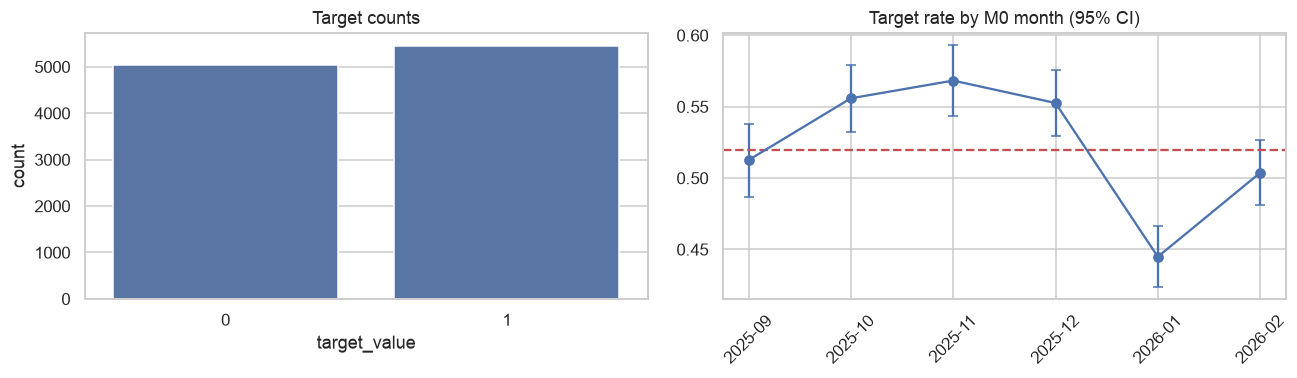

In [5]:
def rate_table(d, col, target=TARGET, min_n=MIN_N):
    """Target rate by category with Wilson 95% CI and lift vs the overall rate."""
    g = d.groupby(col, observed=True)[target].agg(["count", "sum"]).rename(columns={"sum": "n_pos"})
    g["rate"] = g["n_pos"] / g["count"]
    lo, hi = proportion_confint(g["n_pos"], g["count"], method="wilson")
    g["ci_lo"], g["ci_hi"], g["lift"] = lo, hi, g["rate"] / d[target].mean()
    return g[g["count"] >= min_n].sort_values("count", ascending=False)

rate = clients[TARGET].mean()
print(clients[TARGET].value_counts().sort_index().to_string())
print(f"\nTarget rate (observation level): {rate:.2%}  | imbalance ~ 1:{(1 - rate) / rate:,.2f}")

clients["m0_month"] = clients[M0].dt.to_period("M").astype(str)
m = rate_table(clients, "m0_month", min_n=1).sort_index()
display(m)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sns.countplot(x=TARGET, data=clients, ax=ax[0]); ax[0].set_title("Target counts")
ax[1].errorbar(range(len(m)), m["rate"], yerr=[m["rate"] - m["ci_lo"], m["ci_hi"] - m["rate"]], marker="o", capsize=3)
ax[1].set_xticks(range(len(m))); ax[1].set_xticklabels(m.index, rotation=45); ax[1].axhline(rate, color="r", ls="--")
ax[1].set_title("Target rate by M0 month (95% CI)")
plt.tight_layout(); plt.show()

### 2.3 Numeric account variables

,median_target1,median_target0,AUC,p_value,separation
feature,,,,,
arrears_share_of_due,0.3488,0.2695,0.6917,0.0000,0.3835
m0_arrearsamount,920.6600,688.6050,0.5865,0.0000,0.1730
m0_arrearsamount_slog,6.8262,6.5361,0.5865,0.0000,0.1730
obs_seq,2.0000,1.0000,0.5776,0.0000,0.1551
obs_id,"136,568.0000","118,611.5000",0.5501,0.0000,0.1002
crccreditlimit_slog,9.2104,9.3057,0.4539,0.0000,0.0922
crccreditlimit,"10,000.0000","11,000.0000",0.4539,0.0000,0.0922
days_payment_before_m0,"24,109.0000","24,113.0000",0.4774,0.0001,0.0452
m0_total_due_with_arrears_slog,7.8381,7.8781,0.5060,0.2868,0.0120


AUC > 0.5: higher values go with target = 1. Outcome-period columns are excluded from this table.


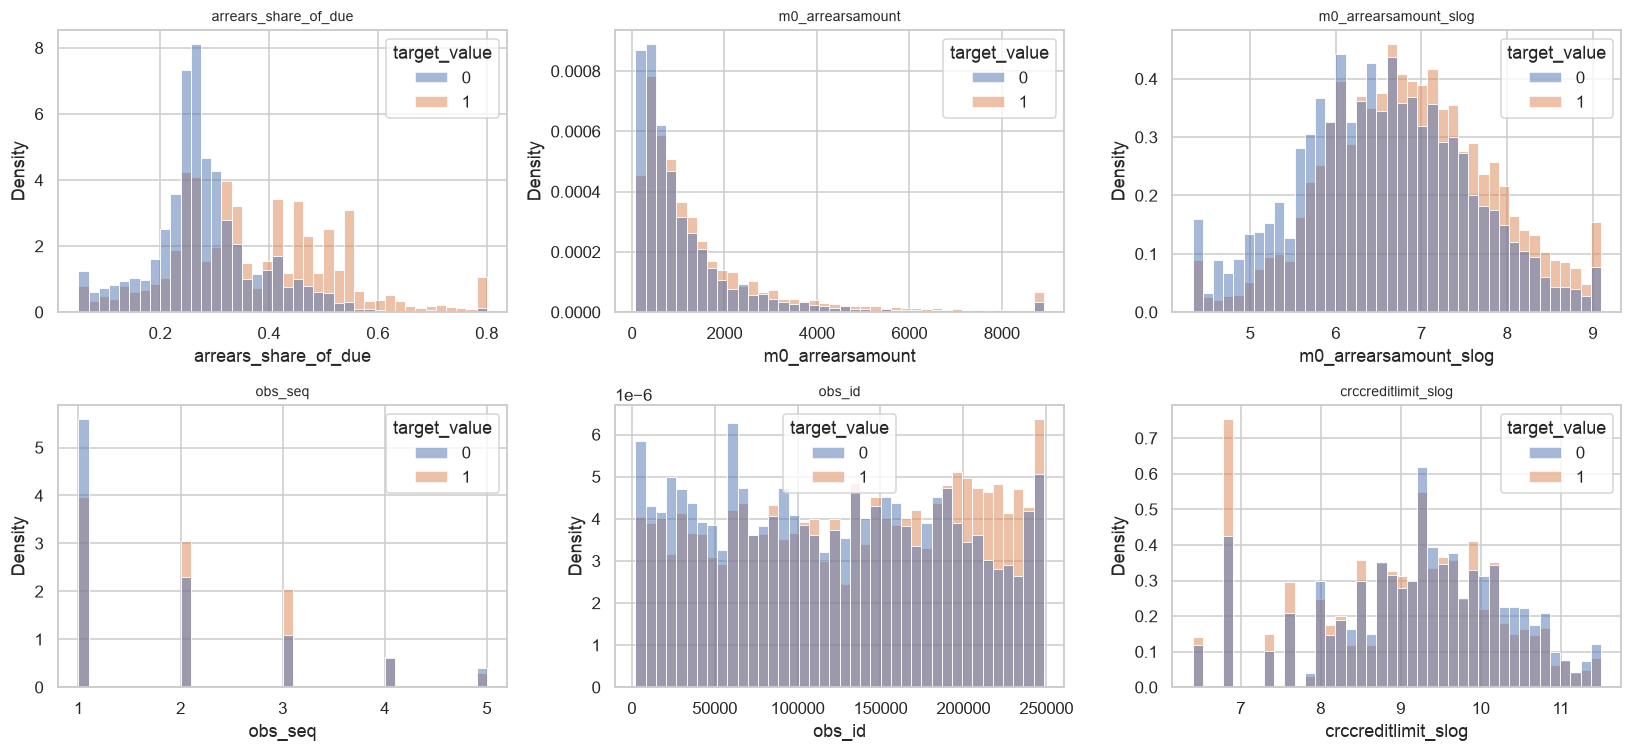

In [7]:
OUTCOME = [c for c in ["payment_count", "total_paid", "total_paid_slog", "target_rule", TARGET] if c in clients.columns]
num = [c for c in clients.select_dtypes("number").columns
       if c not in OUTCOME and c not in ("exclude_flag", "new_to_arrears_flag") and clients[c].nunique() > 2]
rows = []
for c in num:
    a, b = clients.loc[clients[TARGET] == 1, c].dropna(), clients.loc[clients[TARGET] == 0, c].dropna()
    if len(a) > 20 and len(b) > 20:
        u, p = stats.mannwhitneyu(a, b)
        rows.append({"feature": c, "median_target1": a.median(), "median_target0": b.median(), "AUC": u / (len(a) * len(b)), "p_value": p})
auc_clients = pd.DataFrame(rows).set_index("feature").assign(separation=lambda d: (d.AUC - .5).abs() * 2).sort_values("separation", ascending=False)
display(auc_clients)
print("AUC > 0.5: higher values go with target = 1. Outcome-period columns are excluded from this table.")

top = auc_clients.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), top):
    d = clients[[c, TARGET]].dropna(); lo, hi = d[c].quantile([.01, .99]); d[c] = d[c].clip(lo, hi)
    sns.histplot(data=d, x=c, hue=TARGET, stat="density", common_norm=False, bins=40, ax=ax); ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

### 2.4 Label validation (outcome columns)

In [8]:
if {"payment_count", "due_count"} <= set(clients.columns):
    derived = (clients["payment_count"] < clients["due_count"]).astype(int)
    mis = derived != clients[TARGET]
    print(f"target_value vs (payment_count < due_count): disagree for {mis.sum():,} observations ({mis.mean():.2%})")
    display(pd.crosstab(clients[TARGET], derived, rownames=["target_value"], colnames=["payment_count < due_count"]))
    if "target_rule" in clients:
        display(clients.assign(mismatch=mis).groupby("target_rule", observed=True)["mismatch"].agg(["mean", "size"]))
if {"total_paid", "m0_total_due_with_arrears"} <= set(clients.columns):
    ratio = clients["total_paid"] / clients["m0_total_due_with_arrears"].replace(0, np.nan)
    display(ratio.groupby(clients[TARGET]).describe().T)
    print("If target = 1 goes with a ratio near 0 and target = 0 with a ratio near 1, the label is amount-based, not count-based.")
if "payment_count" in clients:
    print(f"\npayment_count: mean {clients.payment_count.mean():.2f}, p99 {clients.payment_count.quantile(.99):.0f}, max {clients.payment_count.max()}"
          f" | due_count max {clients.due_count.max() if 'due_count' in clients else 'n/a'}")

target_value vs (payment_count < due_count): disagree for 1,887 observations (17.97%)


payment_count < due_count,0,1
target_value,,
0,4748,298
1,1589,3864


,mean,size
target_rule,,
4) Payments Received <= 0,0.1382,2822
6) Payments Received >= Payments Due,0.0575,4924
5) Payments Received < Payments Due,0.4016,2343
7) DiA more at end of PW,0.8932,281
2) Last Balance Amount < 250,0.1230,122
8) DiA more at last posted trx,1.0000,7


target_value,0,1
count,"5,046.0000","5,453.0000"
mean,1.7390,0.2076
std,2.8804,0.3272
min,0.0000,-0.7201
25%,0.9506,0.0000
50%,1.0000,0.0000
75%,1.2617,0.3970
max,99.3690,7.9622


If target = 1 goes with a ratio near 0 and target = 0 with a ratio near 1, the label is amount-based, not count-based.

payment_count: mean 3.22, p99 13, max 109 | due_count max 3


### 2.5 Customers with several observations

In [9]:
per_cust = clients.groupby(ID).size()
display(per_cust.value_counts().sort_index().rename("customers").to_frame().assign(share=lambda d: d.customers / d.customers.sum()))
multi = clients[clients[ID].isin(per_cust[per_cust > 1].index)]
if len(multi):
    cons = multi.groupby(ID)[TARGET].agg(["mean", "size"])
    print(f"Customers with >1 observation: {len(cons):,} ({len(cons) / n_cust:.1%}); observations they contribute: {len(multi):,} ({len(multi) / n_obs:.1%})")
    print(f"Of these, target identical across all their observations: {((cons['mean'] == 0) | (cons['mean'] == 1)).mean():.1%}")
    print("-> Observations from the same customer are NOT independent. Split train/test by CUSTOMER (group k-fold) to avoid leakage.")
    if "new_to_arrears_flag" in clients:
        display(clients.groupby(clients.duplicated(ID, keep=False))["new_to_arrears_flag"].mean().rename("new_to_arrears rate (False = single obs)").to_frame())

,customers,share
1,2187,0.4375
2,1140,0.2280
3,1024,0.2048
4,380,0.0760
5,168,0.0336
6,100,0.0200


Customers with >1 observation: 2,812 (56.3%); observations they contribute: 8,312 (79.2%)
Of these, target identical across all their observations: 75.4%
-> Observations from the same customer are NOT independent. Split train/test by CUSTOMER (group k-fold) to avoid leakage.


,new_to_arrears rate (False = single obs)
False,0.9209
True,0.3859


## 3. Transactions table

Date range: 2025-05-29 -> 2026-03-07 | rows 3,534,387
Inflows (amount>0): 24.3% | outflows: 75.7% | zero: 0.0%
Balance < 0: 7.9% | balance == 0: 3.9%


,count,mean,std,min,1%,5%,50%,95%,99%,max
obs_id,"3,534,387.0000","124,611.6370","70,507.9515",167.0000,"2,539.0000","14,400.0000","125,061.0000","234,104.0000","246,813.0000","250,996.0000"
days_from_payment,"3,534,387.0000",-45.1577,30.1274,-92.0000,-92.0000,-90.0000,-47.0000,3.0000,6.0000,7.0000
amount,"3,534,387.0000",5.3444,"4,791.7639","-1,442,700.0000","-4,344.0000","-1,200.0000",-50.0000,"1,050.0000","6,345.9086","2,469,229.3700"
balance,"3,534,387.0000","1,739.0374","18,530.6466","-203,031.0100","-40,182.5582","-7,124.7130",672.4400,"12,513.4820","35,821.0140","2,469,263.3500"
amount_slog,"3,534,387.0000",-2.1872,4.6761,-14.1820,-8.3768,-7.0909,-3.9318,6.9575,8.7557,14.7194
balance_slog,"3,534,387.0000",5.2079,4.6771,-12.2211,-10.6012,-8.8715,6.5124,9.4346,10.4863,14.7194
days_before_m0,"3,534,387.0000",51.3285,30.9182,-8.0000,-5.0000,0.0000,54.0000,96.0000,107.0000,131.0000


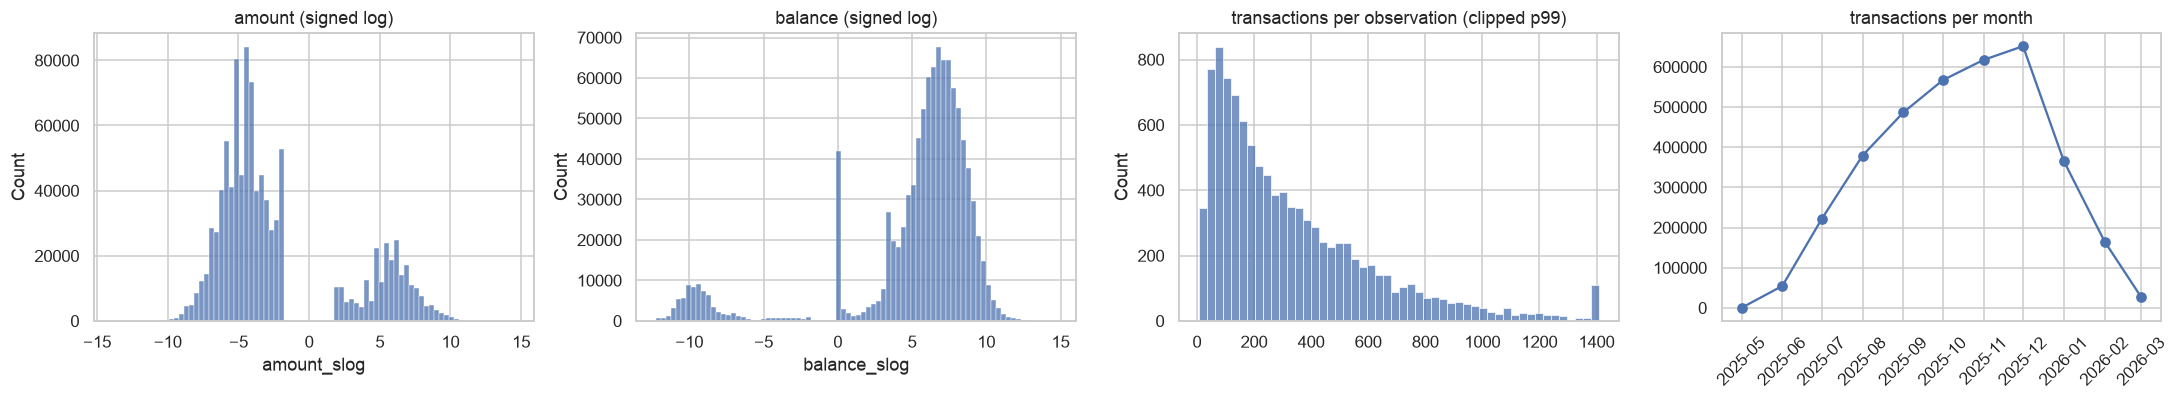

In [10]:
t_dates = txns[TXN_DATE]
print(f"Date range: {t_dates.min().date()} -> {t_dates.max().date()} | rows {len(txns):,}")
print(f"Inflows (amount>0): {(txns[AMT] > 0).mean():.1%} | outflows: {(txns[AMT] < 0).mean():.1%} | zero: {(txns[AMT] == 0).mean():.1%}")
print(f"Balance < 0: {(txns[BAL] < 0).mean():.1%} | balance == 0: {(txns[BAL] == 0).mean():.1%}")
display(txns.select_dtypes("number").describe(percentiles=[.01, .05, .5, .95, .99]).T)

samp = txns.sample(min(PLOT_SAMPLE, len(txns)), random_state=0)
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
sns.histplot(samp["amount_slog"], bins=80, ax=ax[0]); ax[0].set_title("amount (signed log)")
sns.histplot(samp["balance_slog"], bins=80, ax=ax[1]); ax[1].set_title("balance (signed log)")
sns.histplot(tpo.clip(upper=tpo.quantile(.99)), bins=50, ax=ax[2]); ax[2].set_title("transactions per observation (clipped p99)")
mm = txns.groupby(txns[TXN_DATE].dt.to_period("M").dt.to_timestamp()).size()
ax[3].plot(mm.index, mm.values, marker="o"); ax[3].set_title("transactions per month"); ax[3].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
del samp

In [11]:
# Categorical structure: counts, share, net amount, inflow share
for col in [c for c in [TXN_TYPE, SPEND, CAT] if c in txns.columns]:
    g = (txns.groupby(col, observed=True)
             .agg(n=(AMT, "size"), net_amount=(AMT, "sum"), mean_amount=(AMT, "mean"), pct_inflow=(AMT, lambda s: (s > 0).mean()))
             .sort_values("n", ascending=False))
    g["share_%"] = g["n"] / g["n"].sum() * 100
    print(f"\n=== {col}: {len(g)} levels (top 20) ===")
    display(g.head(20))

for col in [c for c in ["tx_period", "days_from_payment"] if c in txns.columns]:
    print(f"\n=== {col} ===")
    display(txns[col].describe().to_frame().T)


=== trantypedesc: 211 levels (top 20) ===


,n,net_amount,mean_amount,pct_inflow,share_%
trantypedesc,,,,,
Card Purchase,907004,"-224,803,053.1500",-247.8523,0.0000,25.6623
Transfer,324576,"-266,852,101.1900",-822.1560,0.0790,9.1834
Transfer Received,277525,"285,870,503.4100","1,030.0712",1.0000,7.8521
Prepaid Purchase,227390,"-10,394,183.5000",-45.7108,0.0000,6.4336
Payment Received,223050,"565,949,395.9900","2,537.3208",1.0000,6.3109
Immediate Payment,188757,"-167,140,819.7400",-885.4814,0.0000,5.3406
Voucher Purchase,111163,"-12,314,928.5000",-110.7826,0.0000,3.1452
Immediate Capitec Pay Payment,89644,"-21,865,677.1800",-243.9168,0.0000,2.5363
Cash Withdrawal,89555,"-71,628,949.0500",-799.8319,0.0000,2.5338



=== spendgroup: 38 levels (top 20) ===


,n,net_amount,mean_amount,pct_inflow,share_%
spendgroup,,,,,
InternalTransfer,673475,"16,259,975.3600",24.1434,0.4544,19.0549
CardAuthorisationTransaction,532780,"-134,468,157.4500",-252.3896,0.0001,15.0742
CardTransaction,525686,"-134,803,545.3500",-256.4336,0.0018,14.8735
MoneyIn,310888,"638,093,382.2400","2,052.4864",0.9985,8.7961
Prepaid,235350,"-10,099,309.5000",-42.9119,0.0285,6.6589
PaymentInternal,206262,"-180,910,169.4100",-877.0892,0.0099,5.8359
Fee,162600,"-1,991,708.2700",-12.2491,0.0125,4.6005
Vouchers,111404,"-12,294,335.5000",-110.3581,0.0022,3.1520
CapitecPay,95070,"-23,680,155.4800",-249.0813,0.0000,2.6899



=== categoryname: 102 levels (top 20) ===


,n,net_amount,mean_amount,pct_inflow,share_%
categoryname,,,,,
Transfer,675813,"15,399,719.3200",22.7870,0.4542,19.1211
Groceries,441512,"-98,657,431.4000",-223.4536,0.0001,12.4919
Other Income,260225,"349,121,980.8500","1,341.6158",0.9995,7.3627
Cellphone,253735,"-13,691,959.3500",-53.9617,0.0175,7.1790
Betting/Lottery,237072,"-26,856,008.4500",-113.2821,0.0633,6.7076
Digital Payments,227111,"-227,328,413.7200","-1,000.9573",0.0038,6.4258
Fees,162600,"-1,991,708.2700",-12.2491,0.0125,4.6005
Cash Withdrawal,141456,"-93,712,922.0100",-662.4881,0.0249,4.0023
Uncategorised,112910,"10,871,132.3700",96.2814,0.5061,3.1946



=== tx_period ===


,count,unique,top,freq
tx_period,3534387,2,pre,3182107



=== days_from_payment ===


,count,mean,std,min,25%,50%,75%,max
days_from_payment,"3,534,387.0000",-45.1577,30.1274,-92.0000,-71.0000,-47.0000,-21.0000,7.0000


### 3.1 Timing and window coverage

Transactions after M0 (negative days): 145,035 (4.10%)


,count,mean,std,min,5%,25%,50%,75%,95%,max
days since last txn (min days_before_m0),"10,499.0000",-0.7164,7.0949,-8.0000,-8.0000,-6.0000,-2.0000,1.0000,16.0000,54.0000
history length (max days_before_m0),"10,499.0000",97.9694,7.4059,56.0000,90.0000,93.0000,96.0000,100.0000,114.0000,131.0000


Observations with no transaction in the last 14 days before M0: 6.0%


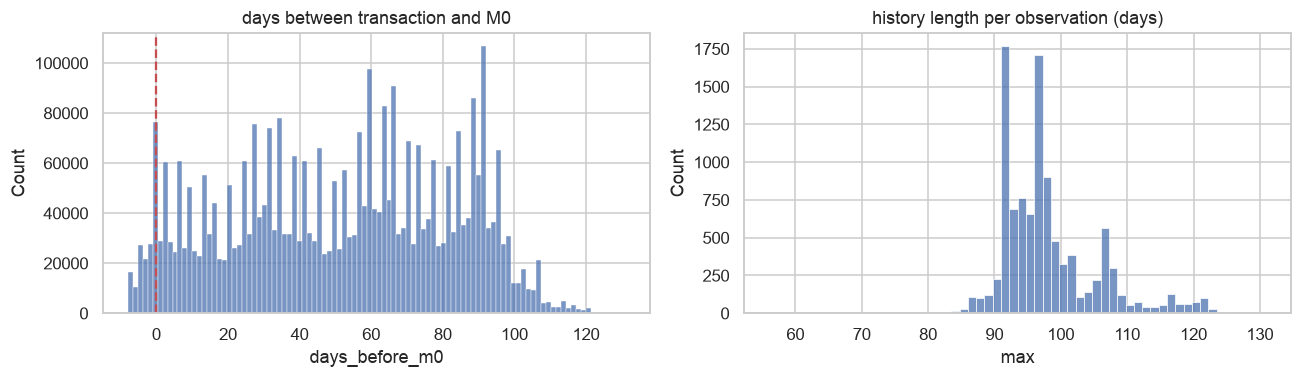

,count,mean,std,min,25%,50%,75%,max
payment_date - last txn (days),"10,499.0000","-24,096.9791",51.5485,"-24,168.0000","-24,118.0000","-24,117.0000","-24,067.0000","-23,968.0000"
M0 - last txn (days),"10,499.0000",-0.7164,7.0949,-8.0000,-6.0000,-2.0000,1.0000,54.0000


Last transaction within 1 day of payment_date: 0.0% | within 1 day of M0: 16.4%
A high share near payment_date means the extract ends at payment_date, not M0: measure recency from there.


In [12]:
d = txns["days_before_m0"].astype("float")
print(f"Transactions after M0 (negative days): {(d < 0).sum():,} ({(d < 0).mean():.2%})")
cov = txns.groupby(KEY, observed=True)["days_before_m0"].agg(["min", "max"]).astype("float")
display(cov.describe(percentiles=[.05, .25, .5, .75, .95]).T.rename(index={"min": "days since last txn (min days_before_m0)", "max": "history length (max days_before_m0)"}))
print(f"Observations with no transaction in the last 14 days before M0: {(cov['min'] > 14).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sns.histplot(d.dropna().clip(-30, 400), bins=100, ax=ax[0]); ax[0].axvline(0, color="r", ls="--"); ax[0].set_title("days between transaction and M0")
sns.histplot(cov["max"].clip(upper=400), bins=60, ax=ax[1]); ax[1].set_title("history length per observation (days)")
plt.tight_layout(); plt.show()

# Is the window anchored on payment_date rather than M0?
if PAY in clients:
    last = txns.groupby(KEY, observed=True)[TXN_DATE].max().rename("last_txn").reset_index()
    last[ID] = last[ID].astype(str)
    chk = clients[KEY + [M0, PAY]].merge(last, on=KEY, how="inner")
    gp, gm = (chk[PAY] - chk["last_txn"]).dt.days, (chk[M0] - chk["last_txn"]).dt.days
    display(pd.concat([gp.describe().rename("payment_date - last txn (days)"), gm.describe().rename("M0 - last txn (days)")], axis=1).T)
    print(f"Last transaction within 1 day of payment_date: {(gp.abs() <= 1).mean():.1%} | within 1 day of M0: {(gm.abs() <= 1).mean():.1%}")
    print("A high share near payment_date means the extract ends at payment_date, not M0: measure recency from there.")

## 4. Linking the tables: behaviour in the window vs the target

Observation-level behavioural aggregates, computed from transactions **on or before M0** only (`days_before_m0 >= 0`).
`bal_last` is the last balance in the window (snapshot), the rest are window aggregates. These are exploratory
associations, not a model.

In [13]:
w = txns[txns["days_before_m0"].astype("float") >= 0]
w = w.assign(inflow=w[AMT].clip(lower=0), outflow=(-w[AMT]).clip(lower=0),
             neg=(w[BAL] < 0).astype("int8"), zero=(w[BAL] == 0).astype("int8"))
g = w.groupby(KEY, observed=True)
agg = g.agg(n_txn=(AMT, "size"), inflow_sum=("inflow", "sum"), outflow_sum=("outflow", "sum"),
            bal_last=(BAL, "last"), bal_mean=(BAL, "mean"), bal_min=(BAL, "min"), bal_std=(BAL, "std"),
            pct_neg_bal=("neg", "mean"), pct_zero_bal=("zero", "mean"),
            days_since_last_txn=("days_before_m0", "min"), history_days=("days_before_m0", "max"))
agg["net_flow"] = agg["inflow_sum"] - agg["outflow_sum"]
agg["outflow_to_inflow"] = agg["outflow_sum"] / agg["inflow_sum"].replace(0, np.nan)
agg["avg_outflow_size"] = agg["outflow_sum"] / (w[AMT] < 0).groupby([w[k] for k in KEY], observed=True).sum().replace(0, np.nan)
agg = agg.astype("float64")
del w

ca = clients.set_index(KEY)
extra = [c for c in ["m0_arrearsamount", "m0_total_due_with_arrears", "arrears_share_of_due", "crccreditlimit", "days_payment_before_m0"] if c in ca]
D = ca[[TARGET] + extra].join(agg, how="left")
print(f"Joined table: {D.shape} | observations with no window transactions: {D['n_txn'].isna().sum():,}")

rows = []
for c in [c for c in D.columns if c != TARGET]:
    a, b = D.loc[D[TARGET] == 1, c].dropna(), D.loc[D[TARGET] == 0, c].dropna()
    if len(a) > 20 and len(b) > 20 and D[c].nunique() > 1:
        u, p = stats.mannwhitneyu(a, b)
        rows.append({"feature": c, "source": "transactions" if c in agg.columns else "account", "median_target1": a.median(),
                     "median_target0": b.median(), "AUC": u / (len(a) * len(b)), "p_value": p})
sep = pd.DataFrame(rows).set_index("feature").assign(separation=lambda d: (d.AUC - .5).abs() * 2).sort_values("separation", ascending=False)
display(sep)

Joined table: (10499, 20) | observations with no window transactions: 0


,source,median_target1,median_target0,AUC,p_value,separation
feature,,,,,,
arrears_share_of_due,account,0.3488,0.2695,0.6917,0.0000,0.3835
pct_zero_bal,transactions,0.0574,0.0237,0.6794,0.0000,0.3588
outflow_to_inflow,transactions,0.9184,1.0454,0.3537,0.0000,0.2925
outflow_sum,transactions,"45,190.4400","85,595.0300",0.3569,0.0000,0.2863
net_flow,transactions,"2,929.6800","-3,111.8950",0.6351,0.0000,0.2703
avg_outflow_size,transactions,280.3851,376.5090,0.3814,0.0000,0.2373
bal_last,transactions,5.9800,100.0800,0.3858,0.0000,0.2285
bal_mean,transactions,316.8727,"1,011.3608",0.3939,0.0000,0.2123
n_txn,transactions,187.0000,284.0000,0.3994,0.0000,0.2011


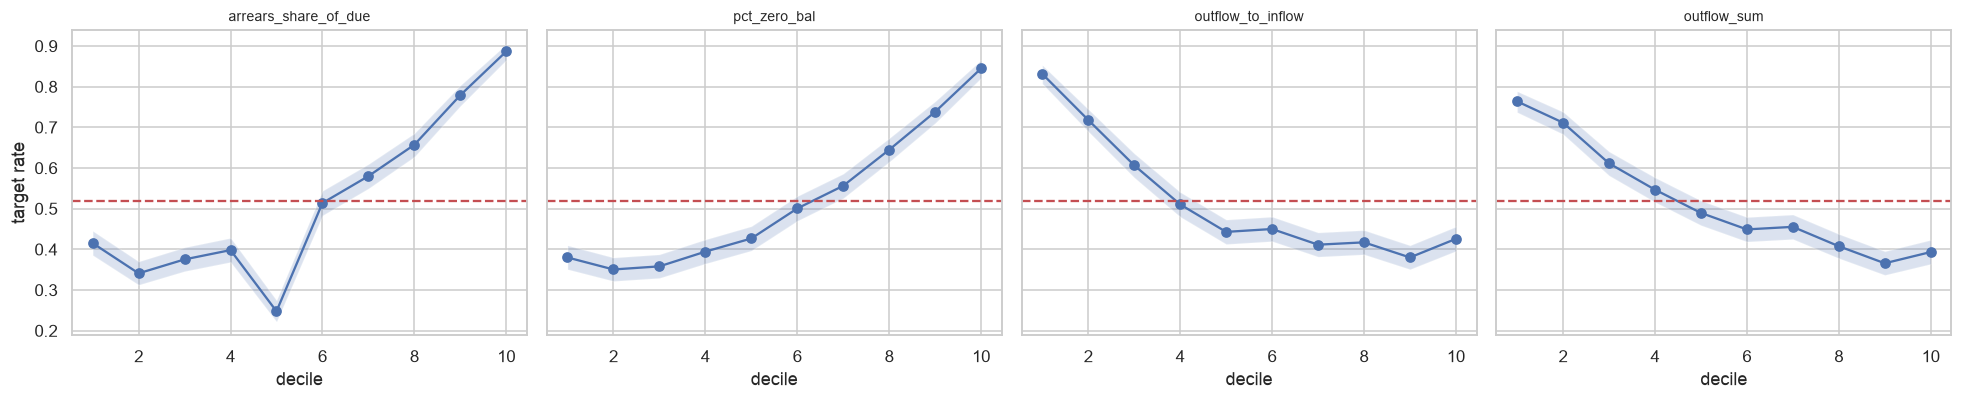

Decile edges of bal_last: [-1.82816100e+05 -1.35323900e+04 -3.21409000e+03 -6.00000000e+00
  1.81000000e+00  3.11700000e+01  8.00800000e+01  2.84750000e+02
  8.30130000e+02  2.84187000e+03  1.18204062e+06]


,count,n_pos,rate,ci_lo,ci_hi,lift
zone,,,,,,
overdrawn,3201,1873,0.5851,0.5680,0.6021,1.1266
0-100,2356,1350,0.5730,0.5529,0.5928,1.1032
100-1000,2082,935,0.4491,0.4278,0.4705,0.8647
>1000,1950,571,0.2928,0.2730,0.3134,0.5638
exactly 0,910,724,0.7956,0.7682,0.8205,1.5318


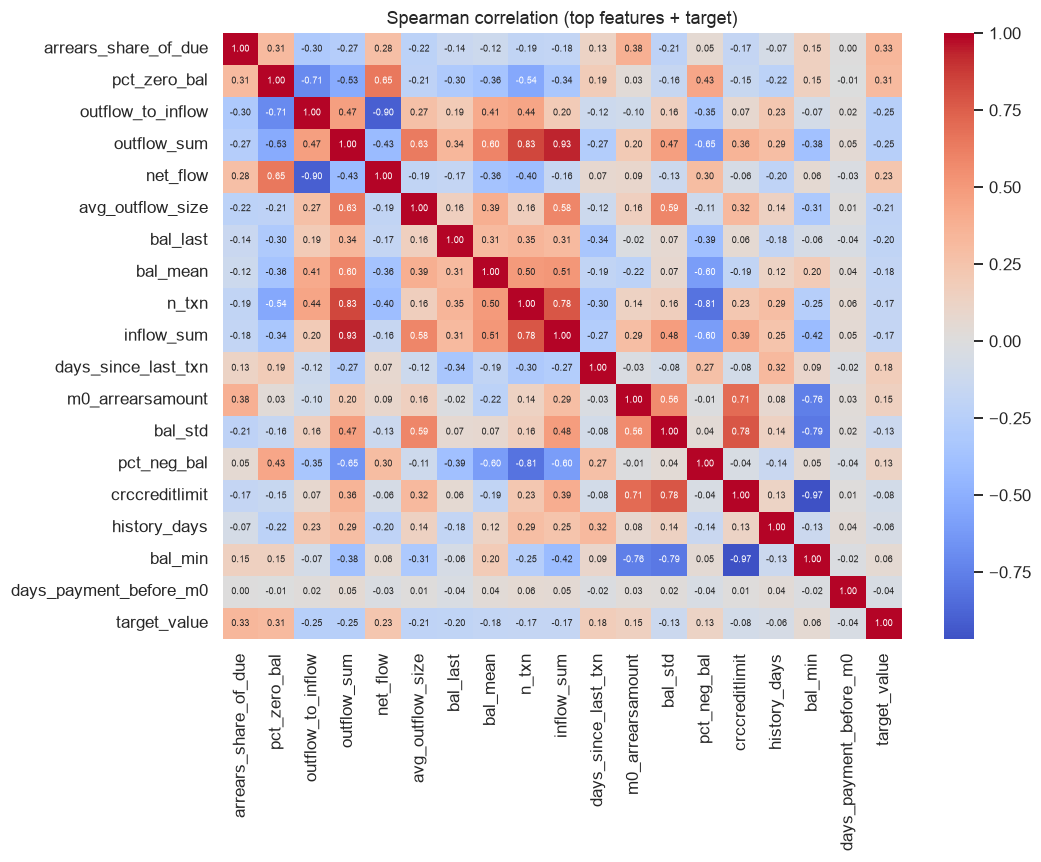

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, c in zip(axes, sep.head(4).index):
    d_ = D[[c, TARGET]].dropna(); d_["decile"] = pd.qcut(d_[c].rank(method="first"), 10, labels=False) + 1
    g_ = d_.groupby("decile")[TARGET].agg(["mean", "count", "sum"]); lo, hi = proportion_confint(g_["sum"], g_["count"], method="wilson")
    ax.plot(g_.index, g_["mean"], marker="o"); ax.fill_between(g_.index, lo, hi, alpha=.2)
    ax.axhline(rate, color="r", ls="--"); ax.set_title(c, fontsize=9); ax.set_xlabel("decile")
axes[0].set_ylabel("target rate"); plt.tight_layout(); plt.show()

if "bal_last" in D:
    b_ = D["bal_last"]
    print("Decile edges of bal_last:", np.round(b_.quantile(np.linspace(0, 1, 11)).values, 2))
    zones = pd.cut(b_, [-np.inf, -1e-9, 1e-9, 100, 1000, np.inf], labels=["overdrawn", "exactly 0", "0-100", "100-1000", ">1000"])
    display(rate_table(pd.DataFrame({"zone": zones, TARGET: D[TARGET]}), "zone", min_n=1))

cols = sep.head(18).index.tolist() + [TARGET]
corr = D[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 6}, ax=ax)
ax.set_title("Spearman correlation (top features + target)"); plt.tight_layout(); plt.show()

In [15]:
# Category-level risk: observations that transacted in a category during the window vs the target rate
if CAT in txns.columns:
    pair = (txns.loc[txns["days_before_m0"].astype("float") >= 0, KEY + [CAT]]
                .groupby(KEY + [CAT], observed=True).size().rename("n").reset_index())
    pair[ID] = pair[ID].astype(str)
    pair = pair.merge(clients[KEY + [TARGET]], on=KEY, how="left")
    rt = rate_table(pair, CAT, min_n=50)
    print(f"Overall target rate {rate:.2%}. Categories with highest lift (presence only: weak when the behaviour is common):")
    display(rt.sort_values("lift", ascending=False).head(15)); display(rt.sort_values("lift").head(10))
    del pair

Overall target rate 51.94%. Categories with highest lift (presence only: weak when the behaviour is common):


,count,n_pos,rate,ci_lo,ci_hi,lift
categoryname,,,,,,
Investment Income,51,32,0.6275,0.4903,0.7468,1.3057
UIF Received,617,386,0.6256,0.5868,0.6629,1.3019
Savings,1112,638,0.5737,0.5445,0.6025,1.1939
Home Insurance,275,149,0.5418,0.4828,0.5997,1.1275
Credit Card Payments,7951,4252,0.5348,0.5238,0.5457,1.1128
Loan Payments,2832,1507,0.5321,0.5137,0.5505,1.1073
Vehicle Payments,887,472,0.5321,0.4992,0.5648,1.1073
Loans,847,448,0.5289,0.4953,0.5623,1.1007
Uncategorised,10371,5412,0.5218,0.5122,0.5314,1.0859


,count,n_pos,rate,ci_lo,ci_hi,lift
categoryname,,,,,,
Pets,430,150,0.3488,0.3053,0.3950,0.7259
Rental Income,76,27,0.3553,0.2570,0.4674,0.7393
Garden,210,75,0.3571,0.2954,0.4240,0.7432
Tax,176,63,0.3580,0.2909,0.4311,0.7449
Municipal Bill,219,80,0.3653,0.3044,0.4309,0.7602
Donations,248,92,0.3710,0.3132,0.4326,0.7720
Partner Rewards,355,132,0.3718,0.3232,0.4232,0.7738
Other Entertainment,309,115,0.3722,0.3202,0.4273,0.7745
Medical Aid,211,80,0.3791,0.3164,0.4462,0.7890


## 5. Automatic red-flag checklist

In [16]:
flags = []
if report:
    dup = report["txn_exact_duplicates_removed"] / max(report["txn_raw_rows"], 1)
    flags.append(("Exact duplicate transactions removed within observations", f"{dup:.1%}", dup > 0.05))
if {"payment_count", "due_count"} <= set(clients.columns):
    mis = ((clients["payment_count"] < clients["due_count"]).astype(int) != clients[TARGET]).mean()
    flags.append(("target_value disagrees with payment_count < due_count", f"{mis:.1%}", mis > 0.02))
flags.append(("Customers with more than one observation (needs customer-level splits)", f"{(per_cust > 1).mean():.1%}", (per_cust > 1).any()))
flags.append(("Observations with no transactions", f"{(n_obs - len(tpo)) / n_obs:.1%}", n_obs - len(tpo) > 0))
flags.append(("Transactions dated after M0", f"{(d < 0).mean():.2%}", (d < 0).any()))
flags.append(("Observations with no transaction in the last 14 days before M0", f"{(cov['min'] > 14).mean():.1%}", (cov["min"] > 14).mean() > 0.2))
flags.append(("Transactions with a zero balance", f"{(txns[BAL] == 0).mean():.1%}", (txns[BAL] == 0).mean() > 0.1))
flags.append(("Target-rate range across M0 months (max - min)", f"{m['rate'].max() - m['rate'].min():.1%}", (m["rate"].max() - m["rate"].min()) > 0.10))
if "exclude_flag" in clients:
    flags.append(("Observations with exclude_flag set (decide whether to drop)", f"{clients['exclude_flag'].astype(bool).mean():.1%}", clients["exclude_flag"].astype(bool).any()))
out = pd.DataFrame(flags, columns=["check", "value", "attention"]); out["attention"] = out["attention"].map({True: "CHECK", False: "ok"})
display(out)

,check,value,attention
0,Exact duplicate transactions removed within ob...,21.1%,CHECK
1,target_value disagrees with payment_count < du...,18.0%,CHECK
2,Customers with more than one observation (need...,56.3%,CHECK
3,Observations with no transactions,0.0%,ok
4,Transactions dated after M0,4.10%,CHECK
5,Observations with no transaction in the last 1...,6.0%,ok
6,Transactions with a zero balance,3.9%,ok
7,Target-rate range across M0 months (max - min),12.3%,CHECK
8,Observations with exclude_flag set (decide whe...,0.0%,ok


### Next steps
* Resolve the flagged items (label definition, window anchor, `exclude_flag`) before modelling.
* Split train/test **by customer** (and keep time order across `m0_monthenddate` where possible).
* Carry the strongest features here into the static vs time-aware comparison notebook, using `days_before_m0` for windows.